# Router Stage 1 -- Medical vs Non-Medical Gatekeeper (CliniqAI)

**Task:** binary classification -- is this image a medical scan at all?

**Positive class (`medical`):** images pooled from all 6 trained specialist datasets
(brain_tumor, kidney_stone, diabetic_retinopathy, skin_lesion, pneumonia, breast_histology),
regardless of each dataset's internal diagnosis labels -- we only care that it's *a medical image*.

**Negative class (`non_medical`):** `cifar10` + `imagenet_subset`, already on disk from earlier
router work.

**Why this is an easy task:** natural photos and medical scans look nothing alike visually, so
this should comfortably clear 97-100% -- consistent with what you saw building the earlier 3-class
flat router.

**Config (matches your specialists):** EfficientNet-B0, batch size 32, lr 1e-3, weight decay 1e-4,
early stopping patience 10, 224x224 input, `num_workers=0` (Windows).


## 1. Session setup

In [27]:
import os
import sys

PROJECT_ROOT = r"E:\programming\CliniqAI"
os.chdir(PROJECT_ROOT)
sys.path.insert(0, PROJECT_ROOT)

print("Working directory:", os.getcwd())

Working directory: E:\programming\CliniqAI


## 2. Configure dataset roots

**Check these paths before running** -- adjust any that don't match your actual folder names.
Every path is scanned recursively for images, so it doesn't matter how each dataset organizes
its internal class subfolders.

In [28]:
from pathlib import Path

# Modality name -> root folder containing that dataset (searched recursively)
MEDICAL_SOURCES = {
    "brain_mri": Path("data/raw/brain_tumor"),
    "kidney_ct": Path("data/raw/kidney_stone"),
    "retinal": Path("data/raw/diabetic_retinopathy"),
    "skin_lesion": Path("data/raw/skin_lesion"),
    "pneumonia": Path("data/raw/pneumonia"),
    "breast_histology": Path("data/raw/breast_histology"),
}

NON_MEDICAL_SOURCES = {
    "cifar10": Path("data/raw/cifar10"),
    "imagenet_subset": Path("data/raw/imagenet_subset"),
}

# Sanity check -- flags any path that doesn't exist so you can fix it before wasting a scan
all_sources = {**MEDICAL_SOURCES, **NON_MEDICAL_SOURCES}
for name, path in all_sources.items():
    status = "OK" if path.exists() else "MISSING -- fix this path"
    print(f"  {name:<20} {str(path):<45} {status}")

  brain_mri            data\raw\brain_tumor                          OK
  kidney_ct            data\raw\kidney_stone                         OK
  retinal              data\raw\diabetic_retinopathy                 OK
  skin_lesion          data\raw\skin_lesion                          OK
  pneumonia            data\raw\pneumonia                            OK
  breast_histology     data\raw\breast_histology                     OK
  cifar10              data\raw\cifar10                              OK
  imagenet_subset      data\raw\imagenet_subset                      OK


## 3. Extract CIFAR-10 into actual image files

CIFAR-10 is downloaded as pickled batch files (`data_batch_1`, ..., `test_batch`), not individual
images -- nothing to glob until these are decoded and saved as PNGs. This only needs to run once;
subsequent runs skip it if already extracted. `imagenet_subset` is treated as optional -- CIFAR-10
alone (60,000 images) is more than enough non-medical data for this task.

In [29]:
import pickle
import numpy as np
from PIL import Image as PILImage

def extract_cifar10(pickle_dir: Path, output_dir: Path):
    if output_dir.exists() and any(output_dir.glob("*.png")):
        print(f"CIFAR-10 already extracted to {output_dir}, skipping.")
        return
    if not pickle_dir.exists():
        print(f"[warning] {pickle_dir} not found -- can't extract CIFAR-10.")
        return

    output_dir.mkdir(parents=True, exist_ok=True)
    batch_files = sorted(pickle_dir.glob("data_batch_*")) + sorted(pickle_dir.glob("test_batch"))
    if not batch_files:
        print(f"[warning] No CIFAR-10 batch files found under {pickle_dir}")
        return

    count = 0
    for batch_file in batch_files:
        with open(batch_file, "rb") as f:
            batch = pickle.load(f, encoding="bytes")
        data = batch[b"data"]
        for i in range(data.shape[0]):
            img_array = data[i].reshape(3, 32, 32).transpose(1, 2, 0)
            img = PILImage.fromarray(img_array)
            img.save(output_dir / f"{batch_file.name}_{i}.png")
            count += 1
        print(f"  extracted {batch_file.name}: {data.shape[0]} images")

    print(f"Total extracted: {count} images -> {output_dir}")

cifar_pickle_dir = NON_MEDICAL_SOURCES["cifar10"] / "cifar-10-batches-py"
cifar_extracted_dir = NON_MEDICAL_SOURCES["cifar10"] / "extracted_images"
extract_cifar10(cifar_pickle_dir, cifar_extracted_dir)

# Point the source at the extracted images, not the raw pickle folder
NON_MEDICAL_SOURCES["cifar10"] = cifar_extracted_dir

if not NON_MEDICAL_SOURCES["imagenet_subset"].exists() or \
   not any(NON_MEDICAL_SOURCES["imagenet_subset"].rglob("*")):
    print(f"[info] imagenet_subset is empty -- proceeding with CIFAR-10 only for non_medical class.")
    del NON_MEDICAL_SOURCES["imagenet_subset"]

CIFAR-10 already extracted to data\raw\cifar10\extracted_images, skipping.
[info] imagenet_subset is empty -- proceeding with CIFAR-10 only for non_medical class.


## 4. Collect image paths per source

Recursively finds every image file under each root. Internal class/patient subfolder structure
is ignored entirely -- for Stage 1 we only need "is this a medical image", not the diagnosis.

In [30]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
MAX_PER_SOURCE = 4000  # cap per dataset so no single source dominates training
RANDOM_SEED = 42

import random
random.seed(RANDOM_SEED)

def collect_images(root, max_count=None):
    if not root.exists():
        print(f"  [skip] {root} does not exist")
        return []
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMAGE_EXTENSIONS]
    if max_count and len(files) > max_count:
        files = random.sample(files, max_count)
    return files

medical_files = []
for modality, root in MEDICAL_SOURCES.items():
    files = collect_images(root, MAX_PER_SOURCE)
    print(f"  {modality:<20} {len(files)} images")
    medical_files.extend(files)

print(f"\nTotal medical images (capped, pooled): {len(medical_files)}")
assert len(medical_files) > 0, "No medical images found -- check MEDICAL_SOURCES paths."

# Match non-medical count roughly to medical count for balance
target_non_medical = len(medical_files)
non_medical_files = []
per_source_cap = target_non_medical // max(len(NON_MEDICAL_SOURCES), 1) + 1
for name, root in NON_MEDICAL_SOURCES.items():
    files = collect_images(root, per_source_cap)
    print(f"  {name:<20} {len(files)} images")
    non_medical_files.extend(files)

if len(non_medical_files) > target_non_medical:
    non_medical_files = random.sample(non_medical_files, target_non_medical)

print(f"Total non-medical images (balanced to match): {len(non_medical_files)}")
assert len(non_medical_files) > 0, (
    "No non-medical images found -- CIFAR-10 extraction may have failed, "
    "check the output of the extraction cell above."
)

  brain_mri            4000 images
  kidney_ct            4000 images
  retinal              3662 images
  skin_lesion          4000 images
  pneumonia            4000 images
  breast_histology     4000 images

Total medical images (capped, pooled): 23662
  cifar10              23663 images
Total non-medical images (balanced to match): 23662


## 5. Build labeled dataframe and split (70/15/15, image-level)

This task doesn't need patient-level splitting -- it's domain recognition (medical vs not), not per-patient diagnosis, so a random image split is appropriate here.

In [31]:
import pandas as pd

records = [(str(p), "medical") for p in medical_files] + \
          [(str(p), "non_medical") for p in non_medical_files]

df = pd.DataFrame(records, columns=["filepath", "label"])
df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)  # shuffle

n = len(df)
n_train = int(0.70 * n)
n_val = int(0.15 * n)

train_df = df.iloc[:n_train].reset_index(drop=True)
val_df = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df = df.iloc[n_train + n_val:].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print()
print(train_df["label"].value_counts())

Train: 33126  Val: 7098  Test: 7100

label
non_medical    16626
medical        16500
Name: count, dtype: int64


## 6. Dataset, transforms, dataloaders

**Performance note:** the Dataset class now lives in `scripts/gatekeeper_dataset.py` instead of
being defined in this notebook. That's required for `num_workers>0` to actually work on Windows
-- worker processes need to `import` the class, which isn't possible for something defined inline
in a notebook cell. This is very likely why your GPU has been sitting at 40-50% utilization
despite full VRAM: with `num_workers=0`, every image decode/resize/augment step ran single-threaded
on the CPU, serialized in front of the GPU instead of overlapping with it.

In [32]:
import sys
SCRIPTS_DIR = str(Path(PROJECT_ROOT) / "scripts")
if SCRIPTS_DIR not in sys.path:
    sys.path.insert(0, SCRIPTS_DIR)

from gatekeeper_dataset import GatekeeperDataset

import torch
from torch.utils.data import DataLoader
from torchvision import transforms

IMG_SIZE = 224
BATCH_SIZE = 64        # raised from 32 -- EfficientNet-B0 leaves headroom on a 4050 at this input size
NUM_WORKERS = 4         # raised from 0 -- now safe since GatekeeperDataset is importable

CLASS_NAMES = ["non_medical", "medical"]
label_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}

# Precompute integer labels once so the Dataset class doesn't depend on any notebook globals
for split_df in (train_df, val_df, test_df):
    split_df["label_idx"] = split_df["label"].map(label_to_idx)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_dataset = GatekeeperDataset(train_df, transform=train_transform)
val_dataset = GatekeeperDataset(val_df, transform=eval_transform)
test_dataset = GatekeeperDataset(test_df, transform=eval_transform)

loader_kwargs = dict(
    num_workers=NUM_WORKERS,
    pin_memory=True,          # speeds up CPU->GPU transfer
    persistent_workers=True,  # avoids respawning workers every epoch
    prefetch_factor=4,        # each worker preloads batches ahead of the GPU needing them
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

print(f"Batches -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

Batches -> train: 518, val: 111, test: 111


## 7. Model -- EfficientNet-B0 (binary head)

In [33]:
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Input size is fixed (224x224 always) -- this lets cuDNN pick faster convolution
# algorithms after a brief warmup instead of re-searching every batch.
torch.backends.cudnn.benchmark = True

model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 2)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=3)

Device: cuda


## 8. Training loop with early stopping (patience=10)

In [34]:
import time
from pathlib import Path

CHECKPOINT_DIR = Path("models/router")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "router_stage1_efficientnet_b0.pt"

NUM_EPOCHS = 20
PATIENCE = 10

best_val_loss = float("inf")
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

def run_epoch(loader, train_mode):
    model.train() if train_mode else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    torch.set_grad_enabled(train_mode)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        if train_mode:
            optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        if train_mode:
            loss.backward()
            optimizer.step()
        total_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += images.size(0)
    return total_loss / total, correct / total

for epoch in range(1, NUM_EPOCHS + 1):
    start = time.time()
    train_loss, train_acc = run_epoch(train_loader, train_mode=True)
    val_loss, val_acc = run_epoch(val_loader, train_mode=False)
    scheduler.step(val_loss)
    elapsed = time.time() - start

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
          f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} val_acc={val_acc:.4f} | "
          f"{elapsed:.1f}s")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save({
            "model_state_dict": model.state_dict(),
            "val_loss": val_loss,
            "val_acc": val_acc,
            "epoch": epoch,
            "class_names": CLASS_NAMES,
        }, CHECKPOINT_PATH)
        print(f"  -> saved new best checkpoint (val_loss={val_loss:.4f})")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered after {epoch} epochs.")
            break

print("\nTraining complete. Best val_loss:", best_val_loss)

Epoch 01/20 | train_loss=0.0102 train_acc=0.9970 | val_loss=0.0041 val_acc=0.9993 | 1701.6s
  -> saved new best checkpoint (val_loss=0.0041)
Epoch 02/20 | train_loss=0.0043 train_acc=0.9988 | val_loss=0.0005 val_acc=0.9999 | 1402.6s
  -> saved new best checkpoint (val_loss=0.0005)
Epoch 03/20 | train_loss=0.0026 train_acc=0.9992 | val_loss=0.0026 val_acc=0.9989 | 1394.4s
Epoch 04/20 | train_loss=0.0027 train_acc=0.9993 | val_loss=0.0136 val_acc=0.9968 | 1402.0s
Epoch 05/20 | train_loss=0.0025 train_acc=0.9993 | val_loss=0.0011 val_acc=0.9999 | 1400.8s
Epoch 06/20 | train_loss=0.0012 train_acc=0.9996 | val_loss=0.0000 val_acc=1.0000 | 1405.2s
  -> saved new best checkpoint (val_loss=0.0000)
Epoch 07/20 | train_loss=0.0034 train_acc=0.9990 | val_loss=0.0016 val_acc=0.9997 | 1422.9s


KeyboardInterrupt: 

## 9. Evaluate on test set

C:\Users\anish\AppData\Local\Temp\ipykernel_16312\458420168.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

Test accuracy: 0.9998591549295774

              precision    recall  f1-score   support

 non_medical       1.00      1.00      1.00      3510
     medical       1.00      1.00      1.00      3590

    accuracy                           1.00      7100
   macro avg       1.00      1.00      1.00      7100
weighted avg       1.00      1.00      1.00      7100



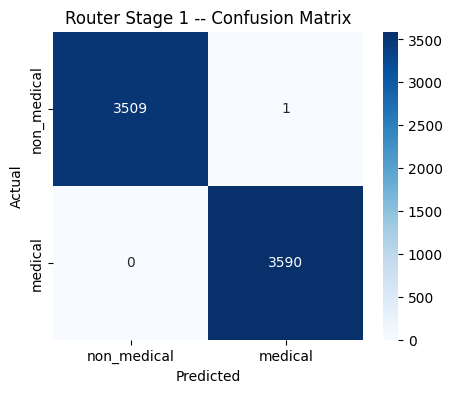

In [35]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test accuracy:", (np.array(all_preds) == np.array(all_labels)).mean())
print()
print(classification_report(all_labels, all_preds, target_names=CLASS_NAMES))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Router Stage 1 -- Confusion Matrix")
plt.show()

## Notes

- **Checkpoint:** `models/checkpoints/router_stage1_efficientnet_b0.pt` -- sync to Drive same as
  your specialists.
- **This model only answers "medical or not"** -- it does NOT tell you which modality. That's
  Stage 2, trained separately, only on the `medical` images.
- If Stage 1 flags something as `non_medical` with high confidence, the backend pipeline should
  reject it before it ever reaches Stage 2 or a specialist.
